# Fase 3 — Avaliação de Desempenho

**Projeto:** Redes Sociais vs Produtividade — Aprendizado de Máquina via Random Forest

Objetivos deste notebook:

1. Carregar o modelo treinado na Fase 2 e fazer previsões no **conjunto de teste**, que o modelo nunca viu.
2. Calcular as métricas de regressão: **R², RMSE e MAE**.
3. Comparar o Random Forest com modelos de referência (*baselines*), para saber se o desempenho é bom de verdade.
4. Visualizar o desempenho: **previsão vs realidade**, resíduos e erro por faixa de produtividade.

## 1. Configuração do ambiente

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import max_error, mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
DATA_DIR = Path("data")
MODEL_DIR = Path("models")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Mesma identidade visual das fases anteriores
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "axes.edgecolor": INK_2, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "legend.frameon": False,
})


def salvar(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")

## 2. Carregamento do modelo e dos dados

In [2]:
metadados = json.loads((MODEL_DIR / "metadata.json").read_text())
ALVO = metadados["alvo"]
FEATURES = metadados["features"]

modelo = joblib.load(MODEL_DIR / "random_forest.joblib")
treino = pd.read_csv(DATA_DIR / "train.csv")
teste = pd.read_csv(DATA_DIR / "test.csv")

X_train, y_train = treino[FEATURES], treino[ALVO]
X_test, y_test = teste[FEATURES], teste[ALVO]

print(f"Modelo: {type(modelo).__name__} com {modelo.n_estimators} árvores")
print(f"Teste: {len(X_test):,} pessoas que o modelo nunca viu")
print(f"R² OOB estimado na Fase 2: {metadados['r2_oob']:.3f}")

Modelo: RandomForestRegressor com 300 árvores
Teste: 5,527 pessoas que o modelo nunca viu
R² OOB estimado na Fase 2: 0.713


## 3. Métricas escolhidas

Como o problema é de **regressão** (Fase 1), Acurácia e F1-Score não se aplicam. Usamos:

| Métrica | O que mede | Como ler |
|---|---|---|
| **R²** (coeficiente de determinação) | Fração da variação da produtividade que o modelo explica | 1 = perfeito; 0 = igual a chutar sempre a média |
| **RMSE** (raiz do erro quadrático médio) | Erro típico, na mesma unidade do score (pontos de 0 a 10) | Penaliza mais os erros grandes |
| **MAE** (erro absoluto médio) | Erro médio em pontos | Mais intuitivo: "em média o modelo erra X pontos" |
| **% dentro de ±1 ponto** | Fração das previsões a no máximo 1 ponto do valor real | Métrica de negócio fácil de comunicar |
| **Erro máximo** | Pior previsão individual | Mostra o pior caso |

In [3]:
def metricas(y_real, y_prev):
    erro = np.abs(y_real - y_prev)
    return {
        "R²": r2_score(y_real, y_prev),
        "RMSE": mean_squared_error(y_real, y_prev) ** 0.5,
        "MAE": mean_absolute_error(y_real, y_prev),
        "% dentro de ±1 ponto": (erro <= 1).mean() * 100,
        "Erro máximo": max_error(y_real, y_prev),
    }


y_pred = modelo.predict(X_test)
y_pred_train = modelo.predict(X_train)

resultado = pd.DataFrame({
    "Treino": metricas(y_train, y_pred_train),
    "Teste": metricas(y_test, y_pred),
}).T
resultado["R² OOB (Fase 2)"] = [np.nan, metadados["r2_oob"]]
resultado.round(3)

,R²,RMSE,MAE,% dentro de ±1 ponto,Erro máximo,R² OOB (Fase 2)
Treino,0.818,0.804,0.615,81.283,3.581,NaN
Teste,0.716,1.005,0.777,71.666,4.694,0.713


**Leitura:**

- No teste, o modelo explica cerca de **72% da variação** da produtividade real e erra em média **~0,78 ponto** numa escala de 0 a 10.
- Cerca de **7 em cada 10** previsões ficam a no máximo 1 ponto do valor real.
- O R² no teste fica praticamente igual ao **R² OOB** estimado na Fase 2. Isso confirma que a validação *out-of-bag* foi uma estimativa honesta e que o modelo **não sofreu overfitting** em relação ao que esperávamos.
- A diferença entre treino (~0,82) e teste (~0,72) é moderada, o que é esperado para uma floresta.

## 4. O desempenho é bom? Comparação com modelos de referência

Uma métrica isolada não diz muito. Comparamos o Random Forest com três referências, todas treinadas **no mesmo conjunto de treino**:

1. **Dummy (média):** sempre prevê a produtividade média do treino. É o piso: qualquer modelo útil precisa superá-lo.
2. **Regressão Linear (todas as features):** o modelo clássico mais simples.
3. **Regressão Linear (só `job_satisfaction_score`):** testa a hipótese da Fase 1 de que quase todo o sinal está em uma única variável.

In [4]:
referencias = {
    "Dummy (sempre a média)": (DummyRegressor(strategy="mean"), FEATURES),
    "Regressão Linear (só satisfação)": (LinearRegression(), ["job_satisfaction_score"]),
    "Regressão Linear (todas as features)": (LinearRegression(), FEATURES),
}

previsoes = {}
for nome, (est, cols) in referencias.items():
    est.fit(X_train[cols], y_train)
    previsoes[nome] = est.predict(X_test[cols])
previsoes["Random Forest"] = y_pred

comparacao = pd.DataFrame({nome: metricas(y_test, p) for nome, p in previsoes.items()}).T
comparacao.round(3)

,R²,RMSE,MAE,% dentro de ±1 ponto,Erro máximo
Dummy (sempre a média),-0.000,1.886,1.615,31.898,4.411
Regressão Linear (só satisfação),0.713,1.011,0.788,70.581,4.297
Regressão Linear (todas as features),0.712,1.011,0.788,70.581,4.366
Random Forest,0.716,1.005,0.777,71.666,4.694


In [5]:
# Bootstrap pareado: reamostramos o conjunto de teste 1.000 vezes e medimos a diferença de R²
# entre o Random Forest e a regressão linear só com satisfação. Se o intervalo de 95% não incluir 0,
# a vantagem do Random Forest é real e não fruto do acaso da amostra de teste.
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
p_rf = previsoes["Random Forest"]
p_lin = previsoes["Regressão Linear (só satisfação)"]

difs, r2s = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    r2_rf = r2_score(y_arr[idx], p_rf[idx])
    r2s.append(r2_rf)
    difs.append(r2_rf - r2_score(y_arr[idx], p_lin[idx]))

ic_r2 = np.percentile(r2s, [2.5, 97.5])
ic_dif = np.percentile(difs, [2.5, 97.5])
print(f"R² do Random Forest no teste: {r2_score(y_test, y_pred):.3f}  (IC 95%: {ic_r2[0]:.3f} a {ic_r2[1]:.3f})")
print(f"Vantagem de R² sobre a Regressão Linear (só satisfação): {np.mean(difs):+.4f}  "
      f"(IC 95%: {ic_dif[0]:+.4f} a {ic_dif[1]:+.4f})")

R² do Random Forest no teste: 0.716  (IC 95%: 0.703 a 0.729)
Vantagem de R² sobre a Regressão Linear (só satisfação): +0.0034  (IC 95%: +0.0004 a +0.0062)


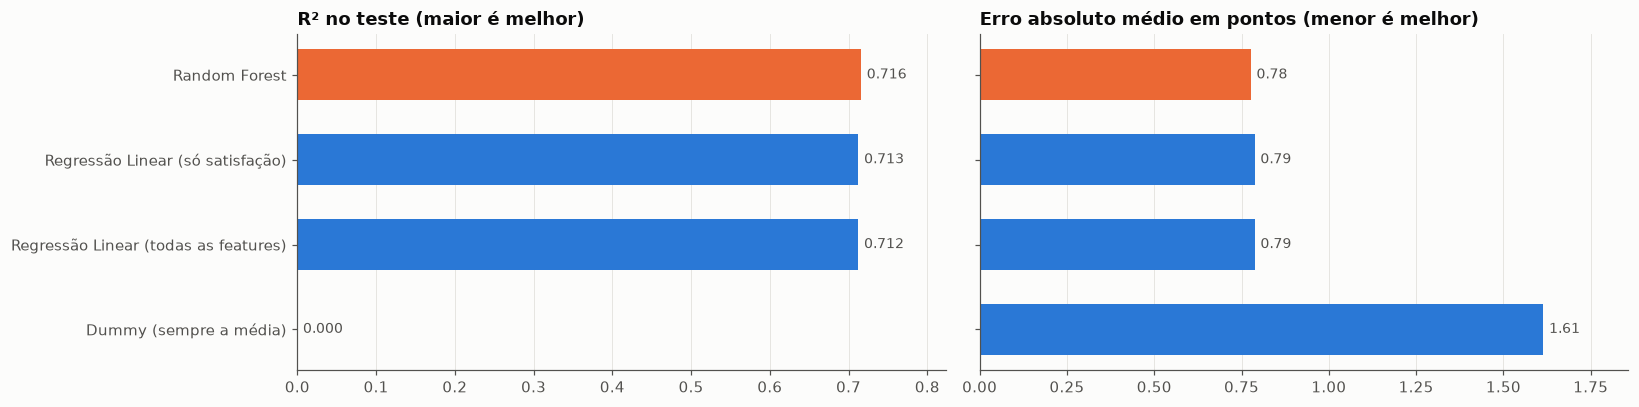

In [6]:
ordem = comparacao.sort_values("R²").index
cores = [ORANGE if n == "Random Forest" else BLUE for n in ordem]

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for ax, col, fmt, titulo in [(axes[0], "R²", "{:.3f}", "R² no teste (maior é melhor)"),
                             (axes[1], "MAE", "{:.2f}", "Erro absoluto médio em pontos (menor é melhor)")]:
    valores = comparacao.loc[ordem, col]
    ax.barh(ordem, valores, color=cores, height=0.6)
    for i, v in enumerate(valores):
        ax.text(v + valores.max() * 0.01, i, fmt.format(0.0 if abs(v) < 5e-4 else v), va="center", fontsize=9, color=INK_2)
    ax.set_xlim(0, valores.max() * 1.15)
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
salvar(fig, "03_comparacao_baselines")
plt.show()

**Leitura (resultado honesto e importante):**

- O Random Forest é **muito melhor que o chute** (Dummy): o R² vai de 0 para ~0,72 e o erro médio cai de ~1,6 para ~0,78 ponto.
- Porém, uma **regressão linear usando só a satisfação com o trabalho** chega praticamente ao mesmo resultado. A vantagem do Random Forest é de apenas **+0,003 de R²**. O bootstrap pareado mostra que essa vantagem é estatisticamente consistente (o intervalo de 95% não inclui zero), mas ela é **pequena demais para ter importância prática**: o erro médio cai só ~0,01 ponto.
- Isso **confirma a EDA da Fase 1**: o sinal está quase todo em uma variável, e a relação é praticamente linear. Não há interações ou não linearidades escondidas para o Random Forest explorar. As 27 features restantes, incluindo **todos os hábitos de redes sociais**, contribuem quase nada.

**Lição de Machine Learning:** um modelo mais sofisticado não cria informação que não está nos dados. O Random Forest fez o que dele se espera: encontrou sozinho, entre 28 variáveis, a única que importa, sem que precisássemos dizer qual era, e ignorou o ruído sem sofrer overfitting. A Fase 4 mostra isso diretamente pela *Feature Importance*.

## 5. Previsão vs realidade

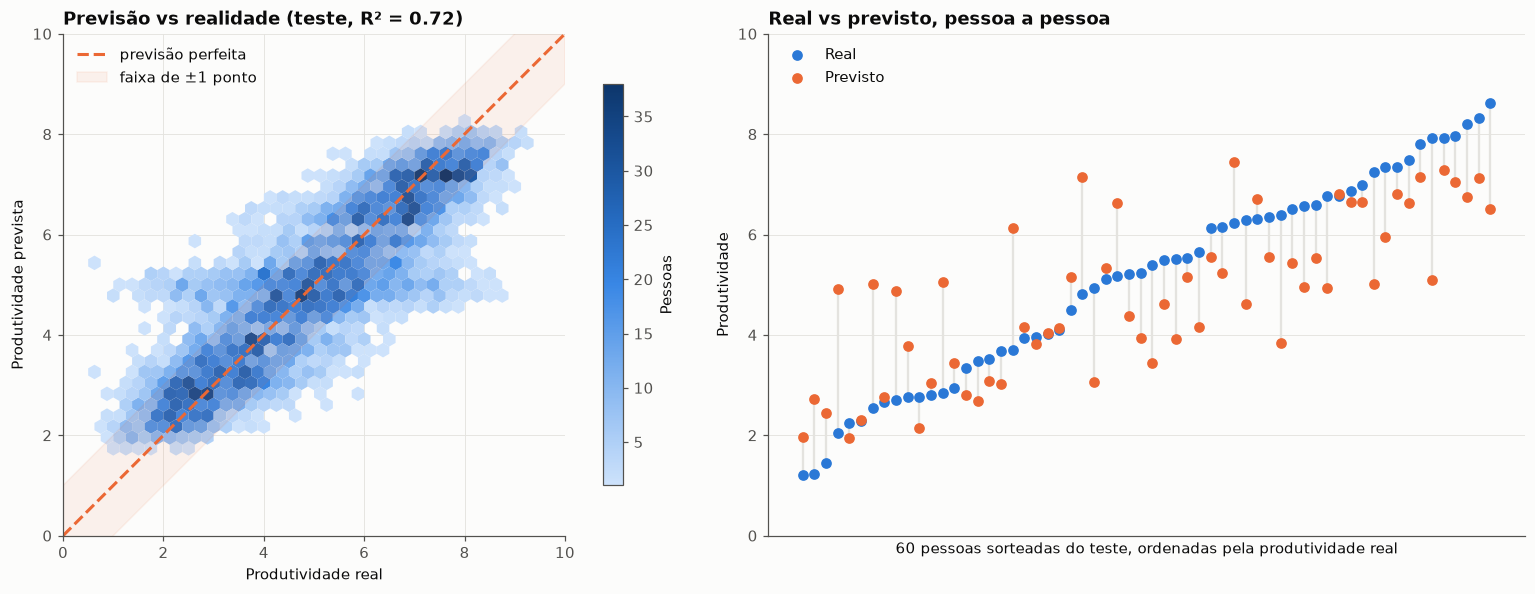

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
hb = ax.hexbin(y_test, y_pred, gridsize=40, cmap=SEQ, mincnt=1, linewidths=0, extent=(0, 10, 0, 10))
ax.plot([0, 10], [0, 10], color=ORANGE, lw=2, ls="--", label="previsão perfeita")
ax.fill_between([0, 10], [-1, 9], [1, 11], color=ORANGE, alpha=0.08, label="faixa de ±1 ponto")
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.set_xlabel("Produtividade real")
ax.set_ylabel("Produtividade prevista")
ax.set_title(f"Previsão vs realidade (teste, R² = {r2_score(y_test, y_pred):.2f})")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="Pessoas", shrink=0.8)

ax = axes[1]
amostra = np.random.default_rng(RANDOM_STATE).choice(len(y_test), 60, replace=False)
ordem_amostra = amostra[np.argsort(y_test.to_numpy()[amostra])]
x = np.arange(len(ordem_amostra))
ax.vlines(x, y_test.to_numpy()[ordem_amostra], y_pred[ordem_amostra], color=GRID, lw=1.5)
ax.scatter(x, y_test.to_numpy()[ordem_amostra], color=BLUE, s=36, zorder=3, label="Real")
ax.scatter(x, y_pred[ordem_amostra], color=ORANGE, s=36, zorder=3, label="Previsto")
ax.set_xticks([])
ax.set_ylim(0, 10)
ax.set_xlabel("60 pessoas sorteadas do teste, ordenadas pela produtividade real")
ax.set_ylabel("Produtividade")
ax.set_title("Real vs previsto, pessoa a pessoa")
ax.legend(loc="upper left")

fig.tight_layout()
salvar(fig, "03_previsto_vs_real")
plt.show()

## 6. Análise dos resíduos

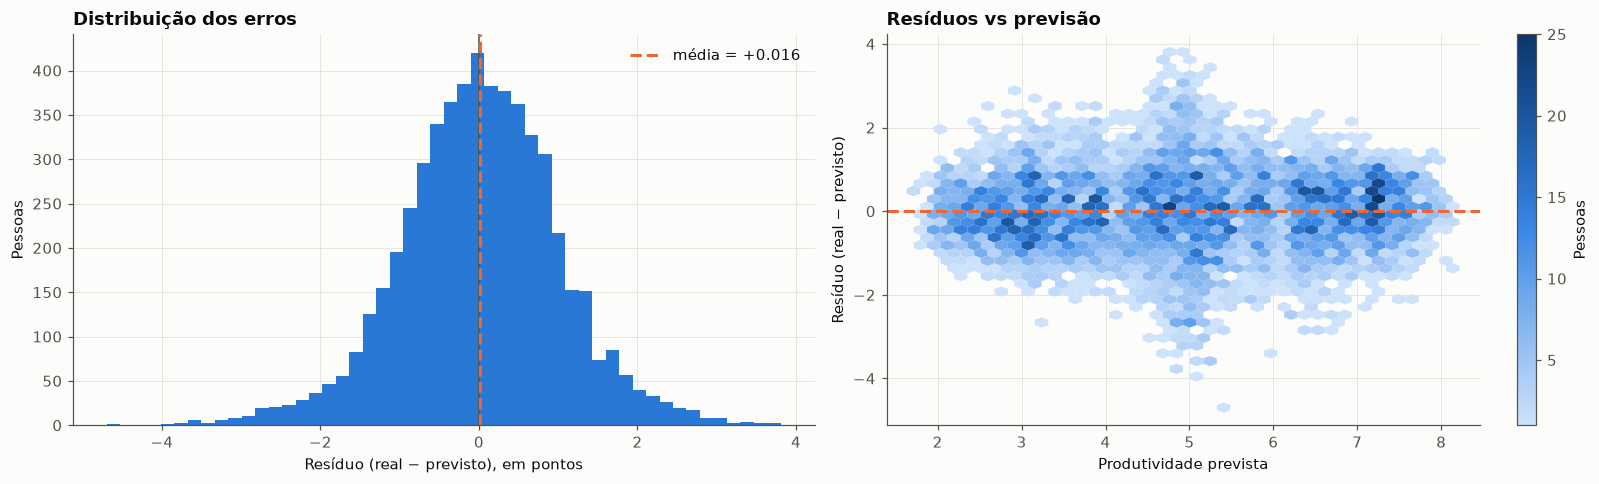

Viés médio (resíduo médio): +0.0164 pontos
Desvio-padrão dos resíduos: 1.005 pontos


In [8]:
residuo = y_test.to_numpy() - y_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

ax = axes[0]
ax.hist(residuo, bins=50, color=BLUE)
ax.axvline(0, color=INK_2, lw=1)
ax.axvline(residuo.mean(), color=ORANGE, lw=2, ls="--", label=f"média = {residuo.mean():+.3f}")
ax.set_xlabel("Resíduo (real − previsto), em pontos")
ax.set_ylabel("Pessoas")
ax.set_title("Distribuição dos erros")
ax.legend()

ax = axes[1]
hb = ax.hexbin(y_pred, residuo, gridsize=40, cmap=SEQ, mincnt=1, linewidths=0)
ax.axhline(0, color=ORANGE, lw=2, ls="--")
ax.set_xlabel("Produtividade prevista")
ax.set_ylabel("Resíduo (real − previsto)")
ax.set_title("Resíduos vs previsão")
fig.colorbar(hb, ax=ax, label="Pessoas")

fig.tight_layout()
salvar(fig, "03_residuos")
plt.show()

print(f"Viés médio (resíduo médio): {residuo.mean():+.4f} pontos")
print(f"Desvio-padrão dos resíduos: {residuo.std():.3f} pontos")

### 6.1 Onde o modelo erra mais? Erro por faixa de produtividade real

In [9]:
faixas = pd.cut(y_test, bins=[0, 2, 4, 6, 8, 10], labels=["0–2", "2–4", "4–6", "6–8", "8–10"])
por_faixa = (pd.DataFrame({"faixa": faixas, "real": y_test, "prev": y_pred, "res": residuo})
             .groupby("faixa", observed=True)
             .agg(pessoas=("res", "size"), real_medio=("real", "mean"), previsto_medio=("prev", "mean"),
                  vies=("res", "mean"), MAE=("res", lambda r: r.abs().mean())))
por_faixa.round(3)

,pessoas,real_medio,previsto_medio,vies,MAE
faixa,,,,,
0–2,264,1.626,2.750,-1.124,1.124
2–4,1652,3.037,3.510,-0.474,0.753
4–6,1775,5.003,4.960,0.042,0.713
6–8,1602,6.944,6.422,0.522,0.766
8–10,234,8.320,7.212,1.108,1.109


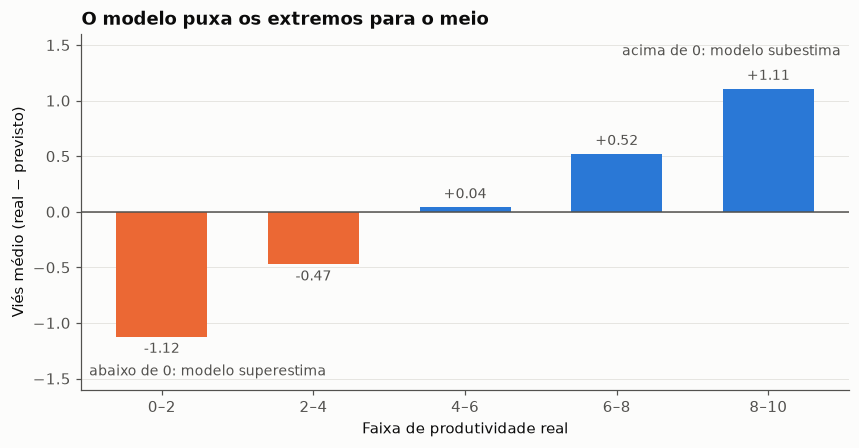

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(por_faixa))
cores_vies = [ORANGE if v < 0 else BLUE for v in por_faixa["vies"]]
ax.bar(x, por_faixa["vies"], color=cores_vies, width=0.6)
ax.axhline(0, color=INK_2, lw=1)
for xi, v in zip(x, por_faixa["vies"]):
    ax.text(xi, v + (0.05 if v >= 0 else -0.05), f"{v:+.2f}", ha="center",
            va="bottom" if v >= 0 else "top", fontsize=9, color=INK_2)
ax.set_xticks(x, por_faixa.index)
ax.set_xlabel("Faixa de produtividade real")
ax.set_ylabel("Viés médio (real − previsto)")
ax.set_ylim(-1.6, 1.6)
ax.set_title("O modelo puxa os extremos para o meio")
ax.text(0.01, 0.04, "abaixo de 0: modelo superestima", transform=ax.transAxes, fontsize=9, color=INK_2)
ax.text(0.99, 0.94, "acima de 0: modelo subestima", transform=ax.transAxes, fontsize=9, color=INK_2, ha="right")
ax.grid(axis="x", visible=False)
salvar(fig, "03_vies_por_faixa")
plt.show()

**Leitura dos resíduos:**

- Os erros têm **média praticamente zero** e distribuição simétrica, em forma de sino. Não há viés global: o modelo não superestima nem subestima todo mundo.
- Mas há um padrão claro por faixa: o modelo **superestima** quem tem produtividade muito baixa e **subestima** quem tem produtividade muito alta, com erros de cerca de ±1 ponto nas pontas. As previsões são "puxadas" para o meio da escala (*regressão à média*).
- Isso acontece porque ~28% da variação da produtividade **não é explicada por nenhuma variável do dataset**. Quando parte do resultado é imprevisível, a melhor estratégia de um modelo que minimiza o erro quadrático é ser conservador e prever valores mais próximos da média. As pessoas nos extremos são justamente aquelas em que o componente imprevisível foi grande.
- Consequência prática para a interface (Fase 6): as previsões vão se concentrar entre ~2 e ~8, raramente chegando aos extremos da escala.

## 7. Salvando as métricas

In [11]:
metricas_finais = {
    "teste": {k: round(float(v), 4) for k, v in metricas(y_test, y_pred).items()},
    "treino": {k: round(float(v), 4) for k, v in metricas(y_train, y_pred_train).items()},
    "r2_oob": metadados["r2_oob"],
    "r2_teste_ic95": [round(float(v), 4) for v in ic_r2],
    "baselines_teste": {nome: round(float(r2_score(y_test, p)), 4) for nome, p in previsoes.items()},
}
(MODEL_DIR / "metrics.json").write_text(json.dumps(metricas_finais, indent=2, ensure_ascii=False))
print(json.dumps(metricas_finais, indent=2, ensure_ascii=False))

{
  "teste": {
    "R²": 0.7159,
    "RMSE": 1.0051,
    "MAE": 0.7766,
    "% dentro de ±1 ponto": 71.6664,
    "Erro máximo": 4.6939
  },
  "treino": {
    "R²": 0.8178,
    "RMSE": 0.8037,
    "MAE": 0.6146,
    "% dentro de ±1 ponto": 81.2828,
    "Erro máximo": 3.5812
  },
  "r2_oob": 0.7131,
  "r2_teste_ic95": [
    0.7028,
    0.729
  ],
  "baselines_teste": {
    "Dummy (sempre a média)": -0.0,
    "Regressão Linear (só satisfação)": 0.7125,
    "Regressão Linear (todas as features)": 0.7125,
    "Random Forest": 0.7159
  }
}


## 8. Resumo e próximos passos

| Pergunta | Resposta |
|---|---|
| O modelo generaliza? | Sim. O R² no teste é praticamente igual ao R² OOB, e a diferença para o treino é moderada. |
| O modelo é útil? | Sim. Explica ~72% da variação e erra em média ~0,78 ponto, contra 1,6 ponto do chute pela média. |
| O Random Forest supera modelos simples? | Só marginalmente. Uma regressão linear apenas com a satisfação no trabalho chega quase ao mesmo resultado. |
| Onde erra? | Nos extremos, puxando as previsões para o centro da escala (regressão à média). |

**Fase 4:** abrir a "caixa-preta" com a *Feature Importance* e analisar, em profundidade, o que o modelo aprendeu sobre o papel das redes sociais na produtividade.